In [33]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from utils.tv_var.periodic_var import PeriodicVAR, select_order

In [34]:
import pickle
from utils.pit.piece_wise_marginal import from_normal

waves_df = pd.read_csv("inputs/waves_bulk.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open("outputs/marginal/transformacion.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

In [35]:
resid = pd.read_csv('outputs/xgb_pit/residuos_horarios.csv', index_col=0, parse_dates=True)

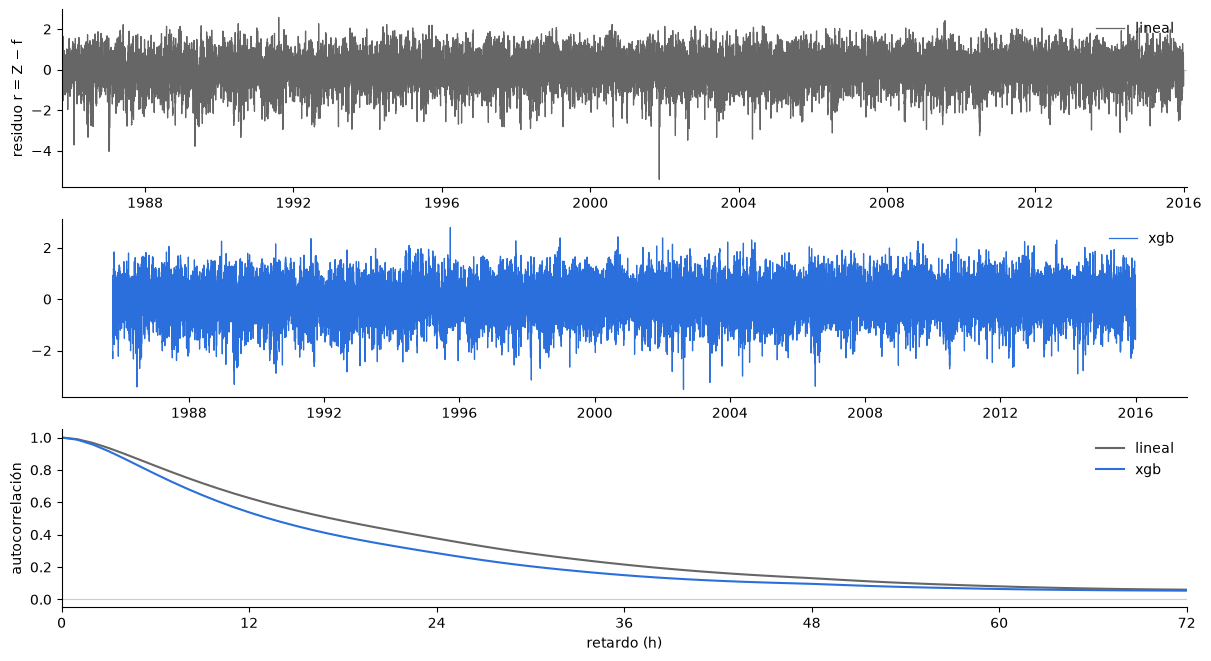

In [36]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

res = {nombre: pd.read_csv(f"outputs/{carpeta}_pit/residuos_horarios.csv", index_col=0, parse_dates=True)
       for nombre, carpeta in [("lineal", "linregs"), ("xgb", "xgb")]}
colores = {"lineal": "0.4", "xgb": "#2a6fdb"}

#### Residuo OOF en malla horaria completa (los huecos quedan como NaN, así los retardos no saltan huecos)
r = {n: d.loc[d.periodo == "oof", "r"].asfreq("h") for n, d in res.items()}
lags_h = np.arange(0, 73)
acf = {n: [s.corr(s.shift(l)) for l in lags_h] for n, s in r.items()}

fig, axs = plt.subplots(3, 1, figsize=(12, 6.5), constrained_layout=True)
t0, t1 = "1985-10-01", "2016-01-31"
i=0
for n, s in r.items():
    axs[i].plot(s.loc[t0:t1], color=colores[n], lw=0.9, label=n)
    axs[2].plot(lags_h, acf[n], color=colores[n], lw=1.5, label=n)
    i=i+1
axs[0].axhline(0, color="0.8", lw=0.8, zorder=0)
axs[0].set(ylabel="residuo r = Z − f", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
axs[2].axhline(0, color="0.8", lw=0.8, zorder=0)
axs[2].set(xlabel="retardo (h)", ylabel="autocorrelación", xticks=np.arange(0, 73, 12), xlim=(0, 72))
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper right")
plt.show()

lineal
decil    1     2     3     4     5     6     7     8     9     10
std    0.71  0.68  0.73  0.73  0.73  0.72  0.69  0.65  0.60  0.72
skew  -0.28 -0.29 -0.41 -0.45 -0.48 -0.52 -0.49 -0.33 -0.13 -0.74
xgb
decil    1     2     3     4     5     6     7     8     9     10
std    0.69  0.70  0.68  0.65  0.63  0.60  0.59  0.57  0.53  0.51
skew  -0.33 -0.16 -0.23 -0.26 -0.22 -0.19 -0.27 -0.30 -0.18 -0.09


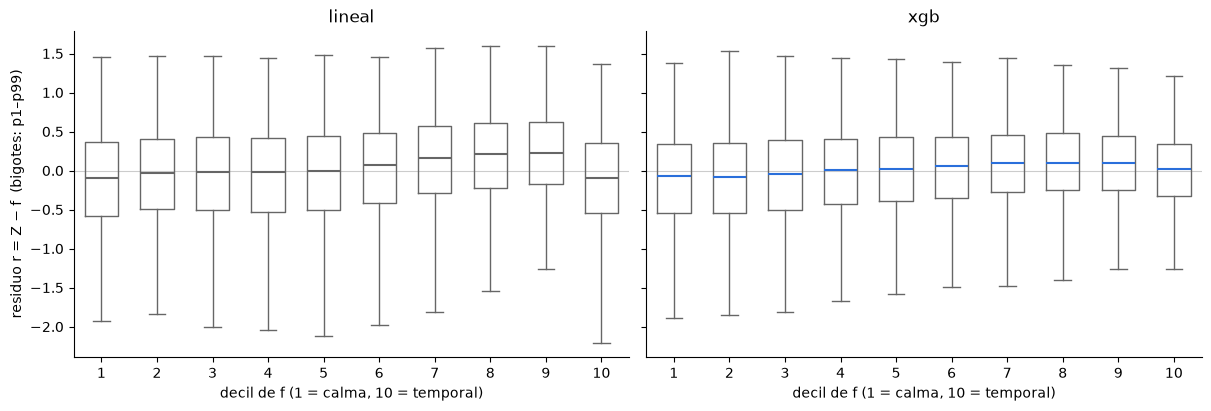

In [37]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for ax, (n, d) in zip(axs, res.items()):
    d = d[d.periodo == "oof"].dropna(subset=["r", "f"])
    d["decil"] = pd.qcut(d["f"], 10, labels=False) + 1
    grupos = [g["r"].values for _, g in d.groupby("decil")]
    ax.boxplot(grupos, whis=(1, 99), showfliers=False, widths=0.6,
               medianprops=dict(color=colores[n], lw=1.5),
               boxprops=dict(color="0.4"), whiskerprops=dict(color="0.4"), capprops=dict(color="0.4"))
    ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.set(title=n, xlabel="decil de f (1 = calma, 10 = temporal)")
    ax.spines[["top", "right"]].set_visible(False)
    print(n, d.groupby("decil")["r"].agg(["std", "skew"]).round(2).T.to_string(), sep="\n")
axs[0].set_ylabel("residuo r = Z − f  (bigotes: p1–p99)")
plt.show()

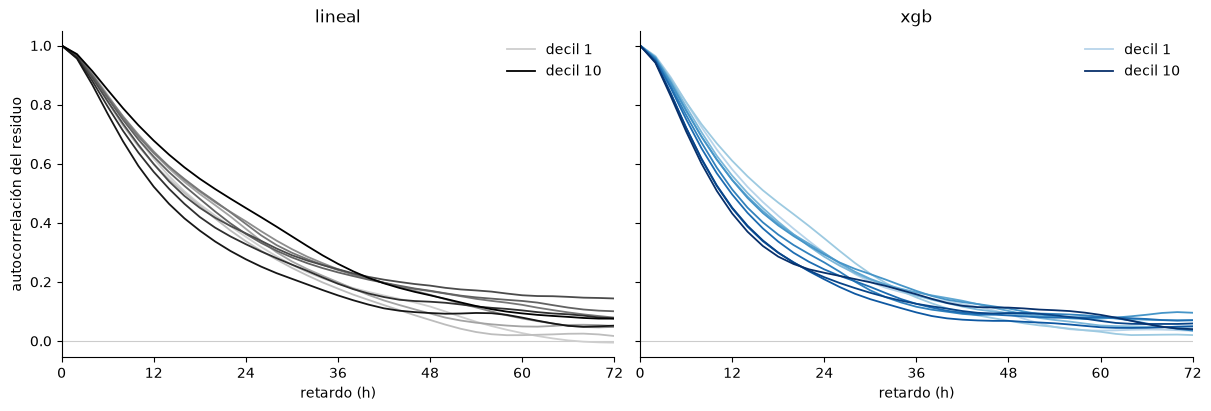

In [38]:
lags_h = np.arange(0, 73, 2)

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for ax, (n, d) in zip(axs, res.items()):
    d = d[d.periodo == "oof"].asfreq("h")                      # malla horaria completa: huecos = NaN
    rv = d["r"].values
    dec = pd.qcut(d["f"], 10, labels=False).values              # decil de f en t (NaN en huecos)
    cmap = plt.cm.Blues if n == "xgb" else plt.cm.Greys
    for k in range(10):
        acf_k = []
        for l in lags_h:
            a, b, dk = rv[:len(rv) - l], rv[l:], dec[:len(rv) - l]
            ok = (dk == k) & ~np.isnan(a) & ~np.isnan(b)
            acf_k.append(np.corrcoef(a[ok], b[ok])[0, 1] if l > 0 else 1.0)
        ax.plot(lags_h, acf_k, color=cmap(0.3 + 0.7 * k / 9), lw=1.3, label=f"decil {k + 1}" if k in (0, 9) else None)
    ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.set(title=n, xlabel="retardo (h)", xticks=np.arange(0, 73, 12), xlim=(0, 72))
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper right")
axs[0].set_ylabel("autocorrelación del residuo")
plt.show()

lineal
decil              1     2     3     4     5     6     7     8     9     10
asimetria       -0.28 -0.29 -0.41 -0.45 -0.48 -0.52 -0.49 -0.33 -0.13 -0.74
exceso_curtosis  0.31  0.48  0.40  0.47  0.58  0.59  0.90  0.55  0.41  2.62
xgb
decil              1     2     3     4     5     6     7     8     9     10
asimetria       -0.33 -0.16 -0.23 -0.26 -0.22 -0.19 -0.27 -0.30 -0.18 -0.09
exceso_curtosis  0.36  0.40  0.31  0.52  0.38  0.41  0.86  0.99  0.53  0.32


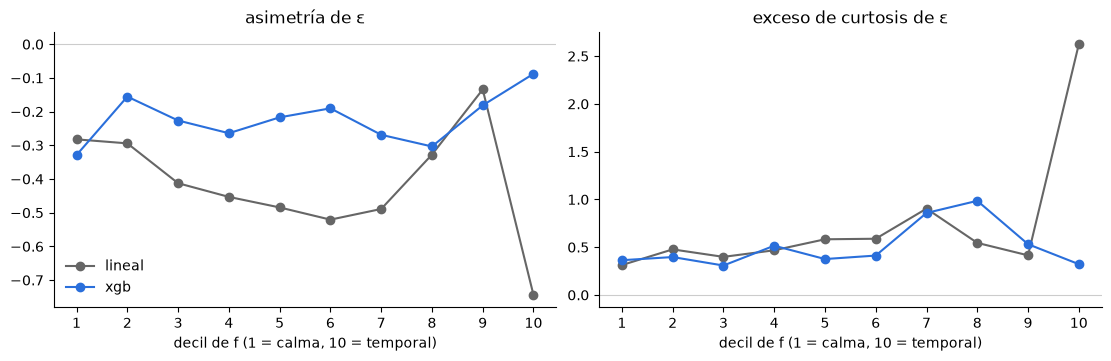

In [39]:
from scipy.stats import skew, kurtosis

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for n, d in res.items():
    d = d[d.periodo == "oof"].dropna(subset=["r", "f"]).copy()
    d["decil"] = pd.qcut(d["f"], 10, labels=False) + 1
    d["eps"] = d["r"] / d.groupby("decil")["r"].transform("std")          # ε = r / σ(decil)
    tabla = d.groupby("decil")["eps"].agg([lambda x: skew(x), lambda x: kurtosis(x)])
    tabla.columns = ["asimetria", "exceso_curtosis"]
    print(n, tabla.round(2).T.to_string(), sep="\n")
    axs[0].plot(tabla.index, tabla["asimetria"], "o-", color=colores[n], label=n)
    axs[1].plot(tabla.index, tabla["exceso_curtosis"], "o-", color=colores[n], label=n)

for ax, t in zip(axs, ["asimetría de ε", "exceso de curtosis de ε"]):
    ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.set(title=t, xlabel="decil de f (1 = calma, 10 = temporal)", xticks=range(1, 11))
    ax.spines[["top", "right"]].set_visible(False)
axs[0].legend(frameon=False)
plt.show()

In [40]:
r_oof = resid.loc[resid.periodo == "oof", ["r"]].asfreq("h")
select_order(r_oof, p_values=[12, 20, 24, 36, 48], n_harm=0, freq="h")

,nobs,loglike,n_params,bic,best
p,,,,,
12,271680,299419.024669,25,-598525.239834,False
20,271680,299683.232581,33,-598953.556617,False
24,271680,299708.219401,37,-598953.480735,False
36,271680,299798.635277,49,-598984.163926,False
48,271680,299908.371990,61,-599053.488789,True


In [41]:
results = PeriodicVAR(p=12, n_harm=0, freq="h").fit(r_oof)
print(results.nobs_, results.resid_.index[0], results.resid_.index[-1])   # ~271 680, 1985 → 2015

271716 1985-01-01 12:00:00 2015-12-31 23:00:00


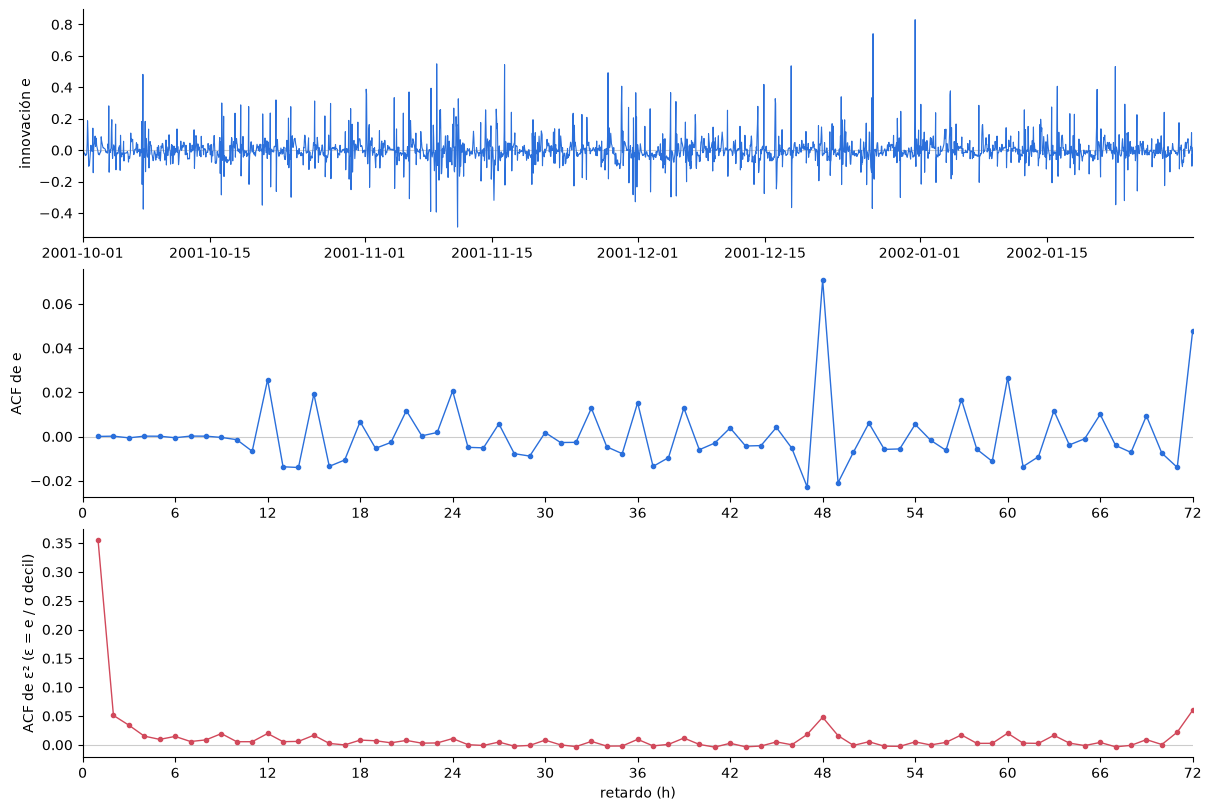

In [42]:
e = results.resid_["r"].asfreq("h")                                  # innovaciones en malla horaria (huecos = NaN)
f_e = resid["f"].reindex(e.index)
decil = pd.qcut(f_e, 10, labels=False)
eps = e / e.groupby(decil).transform("std")                           # innovación estandarizada por su decil

lags_h = np.arange(0, 73)
acf_e = [e.corr(e.shift(l)) for l in lags_h]
acf_eps2 = [(eps**2).corr((eps**2).shift(l)) for l in lags_h]

fig, axs = plt.subplots(3, 1, figsize=(12, 8), constrained_layout=True)
t0, t1 = "2001-10-01", "2002-01-31"
axs[0].plot(e.loc[t0:t1], color="#2a6fdb", lw=0.8)
axs[0].set(ylabel="innovación e", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
axs[1].plot(lags_h[1:], acf_e[1:], "o-", color="#2a6fdb", ms=3, lw=1)
axs[1].set(ylabel="ACF de e")
axs[2].plot(lags_h[1:], acf_eps2[1:], "o-", color="#d1495b", ms=3, lw=1)
axs[2].set(ylabel="ACF de ε² (ε = e / σ decil)", xlabel="retardo (h)")
for ax in axs[1:]:
    ax.set(xticks=np.arange(0, 73, 6), xlim=(0, 72))
for ax in axs:
    ax.axhline(0, color="0.8", lw=0.8, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [43]:
#### Innovaciones del VAR y su f en el mismo instante
e_tr = results.resid_["r"]
f_tr = resid["f"].reindex(e_tr.index)

#### Bordes de los deciles de f (calculados en entrenamiento; se reutilizan al simular)
bordes = np.quantile(f_tr.dropna(), np.linspace(0, 1, 11)[1:-1])     # 9 bordes → 10 deciles
dec_tr = np.digitize(f_tr, bordes)                                     # 0 … 9

#### Un pool de innovaciones por decil
pools = {k: e_tr.values[dec_tr == k] for k in range(10)}
print({k: len(v) for k, v in pools.items()})
print({k: round(v.std(), 3) for k, v in pools.items()})

f_sim = resid.loc["2016":"2025", "f"]                       # f de las PCs históricas (test)
dec_sim = np.digitize(f_sim, bordes)                        # mismos bordes que en entrenamiento

rng = np.random.default_rng(0)
ruido = np.array([pools[k][rng.integers(len(pools[k]))] for k in dec_sim])   # (n_horas,) o (n_horas, k)

{0: 27172, 1: 27171, 2: 27172, 3: 27171, 4: 27172, 5: 27172, 6: 27171, 7: 27171, 8: 27172, 9: 27172}
{0: np.float64(0.084), 1: np.float64(0.089), 2: np.float64(0.084), 3: np.float64(0.082), 4: np.float64(0.077), 5: np.float64(0.079), 6: np.float64(0.082), 7: np.float64(0.08), 8: np.float64(0.079), 9: np.float64(0.073)}


In [44]:
#### f de las PCs históricas en test (2016–2025), malla horaria continua
f_sim = resid.loc["2016-01-01":"2025-12-31", "f"].asfreq("h")
print(f_sim.isna().sum())                       # debe ser 0; si no, f_sim = f_sim.interpolate()

#### Decil de cada hora con los bordes de entrenamiento, y una innovación de su pool
dec_sim = np.digitize(f_sim, bordes)
rng = np.random.default_rng(0)
ruido = np.array([pools[k][rng.integers(len(pools[k]))] for k in dec_sim])
ruido_df = pd.DataFrame(ruido, index=f_sim.index, columns=["r"])

0


In [45]:
r_sim = results.simulate(noise=ruido_df, burn=24*30)["r"]
z_sim = f_sim + r_sim
hs_sim = hs_desde_z(z_sim)

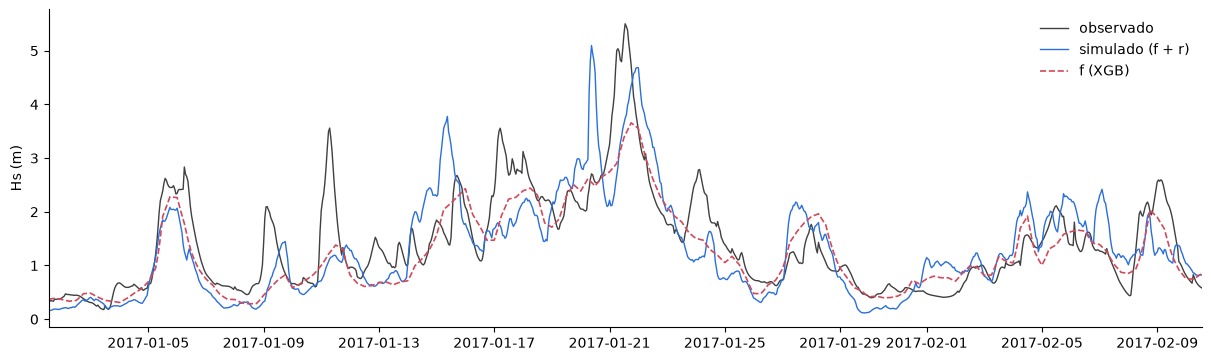

In [46]:
hs_obs = waves_df.loc["2016":"2025", "VHM0"]
hs_f = hs_desde_z(f_sim)  # f pasada a metros

t_max = hs_obs.idxmax()
t0, t1 = t_max - pd.Timedelta(days=20), t_max + pd.Timedelta(days=20)

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.plot(hs_obs.loc[t0:t1], color="0.25", lw=1, label="observado")
ax.plot(hs_sim.loc[t0:t1], color="#2a6fdb", lw=1, label="simulado (f + r)")
ax.plot(hs_f.loc[t0:t1], color="#d1495b", lw=1.2, ls="--", label="f (XGB)")
ax.set(ylabel="Hs (m)", xlim=(t0, t1))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [47]:
r_test = resid.loc[resid.periodo == "test", "r"]
print(f"std r:   real {r_test.std():.3f} | simulada {r_sim.std():.3f}")
print(f"Hs q99:  obs {hs_obs.quantile(0.99):.2f} | sim {hs_sim.quantile(0.99):.2f}")
print(f"Hs máx:  obs {hs_obs.max():.2f} | sim {hs_sim.max():.2f}")

std r:   real 0.632 | simulada 0.619
Hs q99:  obs 2.61 | sim 2.97
Hs máx:  obs 5.50 | sim 5.96


In [48]:
import time
n_sims = 50
hs_sims = []

for i in range(n_sims):
    t = time.time()
    rng = np.random.default_rng(i)
    ruido = np.array([pools[k][rng.integers(len(pools[k]))] for k in dec_sim])
    ruido_df = pd.DataFrame(ruido, index=f_sim.index, columns=["r"])
    r_i = results.simulate(noise=ruido_df, burn=24*30)["r"]
    hs_i = hs_desde_z(f_sim + r_i)
    hs_sims.append(hs_i)             # provisional, hasta meter la PIT
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")

hs_sims = pd.concat(hs_sims, axis=1)                         # (horas, n_sims)

sim 00 (1 s)
sim 01 (1 s)
sim 02 (1 s)
sim 03 (1 s)
sim 04 (1 s)
sim 05 (1 s)
sim 06 (1 s)
sim 07 (1 s)
sim 08 (1 s)
sim 09 (1 s)
sim 10 (1 s)
sim 11 (1 s)
sim 12 (1 s)
sim 13 (1 s)
sim 14 (1 s)
sim 15 (1 s)
sim 16 (1 s)
sim 17 (1 s)
sim 18 (1 s)
sim 19 (1 s)
sim 20 (1 s)
sim 21 (1 s)
sim 22 (1 s)
sim 23 (1 s)
sim 24 (1 s)
sim 25 (1 s)
sim 26 (1 s)
sim 27 (1 s)
sim 28 (1 s)
sim 29 (1 s)
sim 30 (1 s)
sim 31 (1 s)
sim 32 (1 s)
sim 33 (1 s)
sim 34 (1 s)
sim 35 (1 s)
sim 36 (1 s)
sim 37 (1 s)
sim 38 (1 s)
sim 39 (1 s)
sim 40 (1 s)
sim 41 (1 s)
sim 42 (1 s)
sim 43 (1 s)
sim 44 (1 s)
sim 45 (1 s)
sim 46 (1 s)
sim 47 (1 s)
sim 48 (1 s)
sim 49 (1 s)


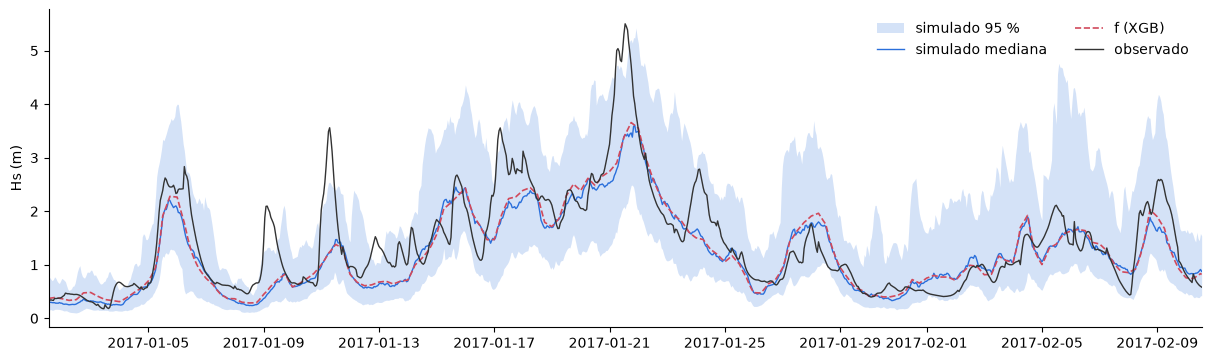

In [49]:
w = hs_sims.loc[t0:t1]
lo, med, hi = w.quantile(0.025, axis=1), w.median(axis=1), w.quantile(0.975, axis=1)

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(w.index, lo, hi, color="#2a6fdb", alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(med, color="#2a6fdb", lw=1, label="simulado mediana")
ax.plot(hs_f.loc[t0:t1], color="#d1495b", lw=1.2, ls="--", label="f (XGB)")
ax.plot(hs_obs.loc[t0:t1], color="0.2", lw=1, label="observado")
ax.set(ylabel="Hs (m)", xlim=(t0, t1))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=2)
plt.show()

In [50]:
q_lo, q_hi = hs_sims.quantile(0.025, axis=1), hs_sims.quantile(0.975, axis=1)
obs = hs_obs.reindex(hs_sims.index)
print(f"por encima: {(obs > q_hi).mean():.1%}  (esperado 2,5 %)")
print(f"por debajo: {(obs < q_lo).mean():.1%}  (esperado 2,5 %)")

por encima: 3.6%  (esperado 2,5 %)
por debajo: 5.1%  (esperado 2,5 %)


In [51]:
stats_sim = pd.DataFrame({"q99": hs_sims.quantile(0.99), "q999": hs_sims.quantile(0.999), "max": hs_sims.max()})
print(f"obs : q99 {hs_obs.quantile(0.99):.2f} | q999 {hs_obs.quantile(0.999):.2f} | max {hs_obs.max():.2f}")
print(stats_sim.quantile([0.025, 0.5, 0.975]).round(2))

obs : q99 2.61 | q999 3.63 | max 5.50
        q99  q999   max
0.025  2.91  4.10  4.97
0.500  3.03  4.42  6.07
0.975  3.15  4.75  7.86


In [52]:
from scipy.signal import find_peaks

def picos_temporales(hs_obs, sims, q=0.99, sep_h=72, ventana_h=24):
    pk, _ = find_peaks(hs_obs.values, height=hs_obs.quantile(q), distance=sep_h)
    filas = []
    for i in pk:
        t = hs_obs.index[i]
        v = slice(t - pd.Timedelta(hours=ventana_h), t + pd.Timedelta(hours=ventana_h))
        m = sims.loc[v].max()                                 # pico de cada simulación en la ventana
        filas.append({"t": t, "obs": hs_obs.iloc[i], "sim_med": m.median(),
                      "sim_lo": m.quantile(0.025), "sim_hi": m.quantile(0.975)})
    d = pd.DataFrame(filas).set_index("t")
    d["ratio"] = d.sim_med / d.obs
    d["dentro"] = (d.obs >= d.sim_lo) & (d.obs <= d.sim_hi)
    return d

d = picos_temporales(hs_obs, hs_sims)          # en cada notebook, con sus simulaciones
print(f"{len(d)} temporales | ratio mediano sim/obs {d.ratio.median():.2f} | "
      f"dentro del 95 %: {d.dentro.mean():.0%}")

60 temporales | ratio mediano sim/obs 0.88 | dentro del 95 %: 97%


In [53]:
L = 6                                                   # longitud del bloque (h)

e_full = results.resid_["r"].asfreq("h")                # innovaciones en malla horaria (huecos = NaN)
ev = e_full.values
f_full = resid["f"].reindex(e_full.index).values
dec_full = np.digitize(f_full, bordes)

# un inicio es válido si las L innovaciones siguientes existen (sin huecos) y hay f en ese instante
n_ini = len(ev) - L + 1
completo = np.convolve(~np.isnan(ev), np.ones(L), "valid") == L
ok = completo & ~np.isnan(f_full[:n_ini])
inicios = {k: np.flatnonzero(ok & (dec_full[:n_ini] == k)) for k in range(10)}
print({k: len(v) for k, v in inicios.items()})

{0: 27172, 1: 27166, 2: 27172, 3: 27171, 4: 27172, 5: 27172, 6: 27171, 7: 27171, 8: 27172, 9: 27172}


In [54]:
def ruido_bloques(dec_sim, L, rng):
    n = len(dec_sim)
    out = np.empty(n)
    t = 0
    while t < n:
        s = rng.choice(inicios[dec_sim[t]])              # inicio de bloque del decil de f en t
        m = min(L, n - t)
        out[t:t + m] = ev[s:s + m]                       # L innovaciones reales consecutivas
        t += m
    return out

In [55]:
ruido = ruido_bloques(dec_sim, L, rng)              # antes: pools[k][rng.integers(...)] por hora

In [56]:
rs = pd.Series(ruido_bloques(dec_sim, L, np.random.default_rng(0)))
print((rs**2).autocorr(1), (e_full**2).autocorr(1))

0.2931601449532924 0.3607418046580937


In [57]:
import time
n_sims = 50
hs_sims_bloques = []

for i in range(n_sims):
    t = time.time()
    rng = np.random.default_rng(i)
    ruido = ruido_bloques(dec_sim, L, rng)                      # ← bloques de L horas
    ruido_df = pd.DataFrame(ruido, index=f_sim.index, columns=["r"])
    r_i = results.simulate(noise=ruido_df, burn=24*30)["r"]
    hs_i = hs_desde_z(f_sim + r_i)
    hs_sims_bloques.append(hs_i)               # provisional, hasta meter la PIT
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")

hs_sims_bloques = pd.concat(hs_sims_bloques, axis=1)

sim 00 (1 s)
sim 01 (1 s)
sim 02 (1 s)
sim 03 (1 s)
sim 04 (1 s)
sim 05 (1 s)
sim 06 (1 s)
sim 07 (1 s)
sim 08 (1 s)
sim 09 (1 s)
sim 10 (1 s)
sim 11 (1 s)
sim 12 (1 s)
sim 13 (1 s)
sim 14 (1 s)
sim 15 (1 s)
sim 16 (1 s)
sim 17 (1 s)
sim 18 (1 s)
sim 19 (1 s)
sim 20 (1 s)
sim 21 (1 s)
sim 22 (1 s)
sim 23 (1 s)
sim 24 (1 s)
sim 25 (1 s)
sim 26 (1 s)
sim 27 (1 s)
sim 28 (1 s)
sim 29 (1 s)
sim 30 (1 s)
sim 31 (1 s)
sim 32 (1 s)
sim 33 (1 s)
sim 34 (1 s)
sim 35 (1 s)
sim 36 (1 s)
sim 37 (1 s)
sim 38 (1 s)
sim 39 (1 s)
sim 40 (1 s)
sim 41 (1 s)
sim 42 (1 s)
sim 43 (1 s)
sim 44 (1 s)
sim 45 (1 s)
sim 46 (1 s)
sim 47 (1 s)
sim 48 (1 s)
sim 49 (1 s)


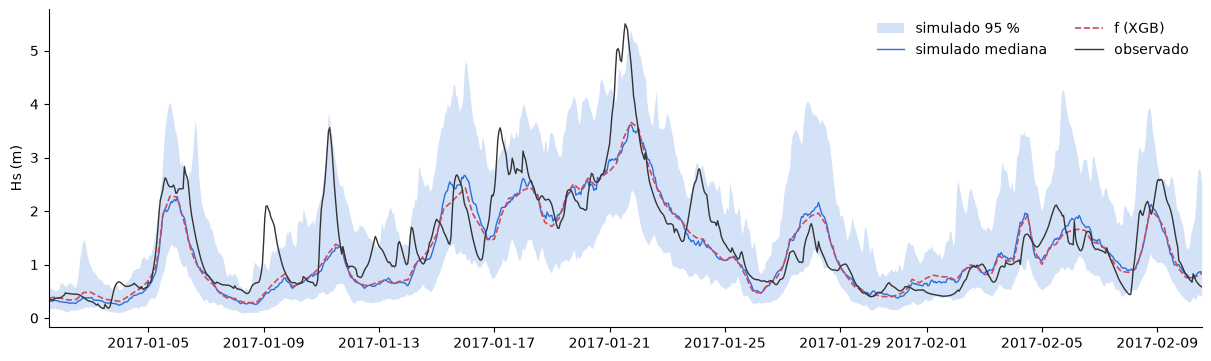

In [58]:
w = hs_sims_bloques.loc[t0:t1]
lo, med, hi = w.quantile(0.025, axis=1), w.median(axis=1), w.quantile(0.975, axis=1)

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(w.index, lo, hi, color="#2a6fdb", alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(med, color="#2a6fdb", lw=1, label="simulado mediana")
ax.plot(hs_f.loc[t0:t1], color="#d1495b", lw=1.2, ls="--", label="f (XGB)")
ax.plot(hs_obs.loc[t0:t1], color="0.2", lw=1, label="observado")
ax.set(ylabel="Hs (m)", xlim=(t0, t1))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=2)
plt.show()

In [59]:
print(f"obs : q99 {hs_obs.quantile(0.99):.2f} | q999 {hs_obs.quantile(0.999):.2f} | max {hs_obs.max():.2f}")
for nombre, sims in [("hora a hora", hs_sims), ("bloques", hs_sims_bloques)]:
    st = pd.DataFrame({"q99": sims.quantile(0.99), "q999": sims.quantile(0.999), "max": sims.max()})
    q_lo, q_hi = sims.quantile(0.025, axis=1), sims.quantile(0.975, axis=1)
    o = hs_obs.reindex(sims.index)
    print(f"\n{nombre}: por encima {(o > q_hi).mean():.1%} | por debajo {(o < q_lo).mean():.1%}")
    print(st.quantile([0.025, 0.5, 0.975]).round(2))

obs : q99 2.61 | q999 3.63 | max 5.50

hora a hora: por encima 3.6% | por debajo 5.1%
        q99  q999   max
0.025  2.91  4.10  4.97
0.500  3.03  4.42  6.07
0.975  3.15  4.75  7.86

bloques: por encima 3.7% | por debajo 5.2%
        q99  q999   max
0.025  2.91  4.13  5.25
0.500  3.05  4.46  6.05
0.975  3.17  5.01  7.43


In [60]:
print(r_test.std(), r_i.std())

0.6319401171706022 0.6397418826074538


In [61]:
from scipy.stats import skew, kurtosis
for nombre, x in [("real (test)", r_test.dropna()), ("simulada", r_i)]:
    print(f"{nombre:12s} asimetría {skew(x):.2f} | exceso de curtosis {kurtosis(x):.2f}")

real (test)  asimetría -0.33 | exceso de curtosis 0.88
simulada     asimetría 0.28 | exceso de curtosis 0.76


In [62]:
from scipy.signal import find_peaks

def picos_temporales(hs_obs, sims, q=0.99, sep_h=72, ventana_h=24):
    pk, _ = find_peaks(hs_obs.values, height=hs_obs.quantile(q), distance=sep_h)
    filas = []
    for i in pk:
        t = hs_obs.index[i]
        v = slice(t - pd.Timedelta(hours=ventana_h), t + pd.Timedelta(hours=ventana_h))
        m = sims.loc[v].max()                                 # pico de cada simulación en la ventana
        filas.append({"t": t, "obs": hs_obs.iloc[i], "sim_med": m.median(),
                      "sim_lo": m.quantile(0.025), "sim_hi": m.quantile(0.975)})
    d = pd.DataFrame(filas).set_index("t")
    d["ratio"] = d.sim_med / d.obs
    d["dentro"] = (d.obs >= d.sim_lo) & (d.obs <= d.sim_hi)
    return d

d = picos_temporales(hs_obs, hs_sims_bloques)          # en cada notebook, con sus simulaciones
print(f"{len(d)} temporales | ratio mediano sim/obs {d.ratio.median():.2f} | "
      f"dentro del 95 %: {d.dentro.mean():.0%}")

60 temporales | ratio mediano sim/obs 0.90 | dentro del 95 %: 98%


In [63]:
def picos(serie, umbral, sep_h=72):
    pk, _ = find_peaks(serie.values, height=umbral, distance=sep_h)
    return serie.iloc[pk].values

u = hs_obs.quantile(0.99)
p_obs = picos(hs_obs, u)
p_sim = [picos(hs_sims_bloques[c], u) for c in hs_sims_bloques.columns]

print(f"nº temporales: obs {len(p_obs)} | sim {np.median([len(p) for p in p_sim]):.0f} "
      f"[{np.percentile([len(p) for p in p_sim], 2.5):.0f}–{np.percentile([len(p) for p in p_sim], 97.5):.0f}]")
for q in [0.5, 0.9]:
    qs = [np.quantile(p, q) for p in p_sim]
    print(f"pico q{int(q*100)}: obs {np.quantile(p_obs, q):.2f} | sim {np.median(qs):.2f} "
          f"[{np.percentile(qs, 2.5):.2f}–{np.percentile(qs, 97.5):.2f}]")

nº temporales: obs 60 | sim 101 [88–114]
pico q50: obs 3.00 | sim 3.20 [3.10–3.41]
pico q90: obs 3.78 | sim 4.44 [4.06–4.74]


In [64]:
#### 1. Cuantiles altos y máximo, sim vs obs
st = pd.DataFrame({"q99": hs_sims_bloques.quantile(0.99), "q999": hs_sims_bloques.quantile(0.999), "max": hs_sims_bloques.max()})
print(f"obs: q99 {hs_obs.quantile(0.99):.2f} | q999 {hs_obs.quantile(0.999):.2f} | max {hs_obs.max():.2f}")
print(st.quantile([0.025, 0.5, 0.975]).round(2))

#### 2. Desviación del residuo, real vs simulado, por decil de f (en test)
d = pd.DataFrame({"f": f_sim, "r_real": resid["r"].reindex(f_sim.index), "r_sim": r_i})
d["decil"] = np.digitize(d["f"], bordes) + 1
print(d.groupby("decil")[["r_real", "r_sim"]].std().round(3).T)

#### 3. ¿En qué decil de f caen los picos de los temporales simulados de sobra?
pk, _ = find_peaks(hs_sims_bloques.iloc[:, 0].values, height=hs_obs.quantile(0.99), distance=72)
print(pd.Series(np.digitize(f_sim.iloc[pk], bordes) + 1).value_counts().sort_index())

obs: q99 2.61 | q999 3.63 | max 5.50
        q99  q999   max
0.025  2.91  4.13  5.25
0.500  3.05  4.46  6.05
0.975  3.17  5.01  7.43
decil      1      2      3      4      5      6      7      8      9      10
r_real  0.641  0.687  0.671  0.672  0.661  0.623  0.599  0.590  0.542  0.516
r_sim   0.676  0.661  0.657  0.648  0.642  0.630  0.630  0.606  0.588  0.581
5      4
6      2
7      5
8      8
9     13
10    60
Name: count, dtype: int64
